<a href="https://colab.research.google.com/github/davidlealo/sic_ia_2026/blob/main/clases/sic_2026_ia_Clase_19.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Revisión de grupos


> Estudiantes: Kamila Arraigada, Alexandra Terrazas

> TEMA: Retinopatía Diabética

> Descripción: Un escaner que permita detectar y clasificar de manera temprana si un paciente tiene retinopatia diabetica. El escaner seria la primera evaluación para determinar si el paciente debe buscar a un experto para iniciar un tratamiento temprano

> Data: Diabetic Retinopathy (Kaggle)



Le preguntamos a CLAUDE y nos dijo: Mi recomendación es no pasarse a Roboflow y, en cambio, **entrenar en los Notebooks de Kaggle con imágenes reducidas**. El problema no es la plataforma sino el tamaño de las imágenes, y eso se resuelve con preprocesamiento.

**Por qué no Roboflow.** Está pensado sobre todo para anotar y entrenar detección de objetos. Aunque admite clasificación, el plan gratuito tiene límites de imágenes y créditos de entrenamiento, y el entrenamiento es casi una caja negra. Para un trabajo de curso, las estudiantes aprenden más armando el pipeline ellas mismas, y pierden poco a cambio.

**Por qué Kaggle Notebooks en vez de Colab.** Ahí el dataset de la competencia ya está montado, así que no hay que descargar ni descomprimir nada. Además dan GPU gratis, del orden de 30 horas semanales. En Colab gratis, el dataset original de la competencia (decenas de GB en archivos 7z partidos) prácticamente no cabe en el disco temporal, y bajarlo cada sesión es inviable.

**Cómo hacerlo manejable:**

1. **Reducir las imágenes una sola vez.** Las originales tienen miles de píxeles por lado, pero el modelo va a trabajar a 224–384 px. Basta un notebook que recorte el borde negro, redimensione a unos 384–512 px, guarde en JPEG y publique el resultado como dataset propio en Kaggle. Así pasan de decenas de GB a unos pocos. También pueden usar alguna versión ya redimensionada de EyePACS que haya en Kaggle, revisando bien de dónde viene.
2. **Submuestrear con criterio.** No necesitan las 35 mil imágenes. Para la tarea binaria (referible / no referible) basta un subconjunto de 5 a 10 mil: todas las de las clases minoritarias y una muestra de la clase 0. Eso además ayuda con el desbalance.
3. **Usar transferencia de aprendizaje liviana.** Por ejemplo, EfficientNet-B0 o ResNet50 preentrenada, primero con el backbone congelado y después con un ajuste fino corto. Con precisión mixta y pocas épocas, cabe sin problemas en la cuota gratuita.
4. **Si insisten en Colab:** que suban el dataset ya reducido (paso 1) y lo copien al disco local `/content` al inicio de cada sesión. Leer imagen por imagen desde Google Drive es muy lento.

**Ojo con usar los dos datasets juntos.** No pude ver el contenido de `dreamer07/eyepacs` porque la página no carga sin sesión. Por el nombre, es muy probable que sea una reorganización de las mismas imágenes de EyePACS de la competencia. Si combinan ambos, pueden terminar con imágenes duplicadas entre entrenamiento y prueba, lo que infla los resultados. Les sugeriría elegir uno solo y, si es la competencia, separar por paciente: los nombres de archivo son del tipo `10_left` / `10_right`, así que ambos ojos de un paciente deben quedar en el mismo conjunto.

¿Quieres que les arme el notebook de preprocesamiento (recorte, redimensionado y split por paciente) para que lo corran en Kaggle?

In [ ]:
# Revisar: https://www.kaggle.com/datasets/tanlikesmath/diabetic-retinopathy-resized

In [ ]:
# Revisar preprocesamiento de datos y split en https://www.kaggle.com/code/saiadi000000/diabetic-retinopathy-eda-aptos-eyepacs

Entendido, sin archivos. Te dejo la ruta para que la hagan ustedes. En cada paso va qué hacer, qué herramienta usar y cómo saber si les resultó. Cuando tengan su código de un paso, me lo muestran y lo revisamos.

**Paso 0. Decidir de dónde salen las imágenes.**
El dataset original de la competencia pesa unos 89 GiB, con 35.126 imágenes de entrenamiento. Por eso no conviene partir desde ahí. Existe una versión redimensionada por el usuario tanlovesmath, con una carpeta `resized_train_cropped` y su archivo de etiquetas `trainLabels_cropped.csv`, que se ha usado en otros proyectos. Búsquenla en Kaggle como "diabetic retinopathy resized". Como referencia de tamaño, otras versiones reducidas del mismo dataset rondan los 4 GiB. Revisen también qué trae `dreamer07/eyepacs`, pero usen solo uno de los dos.
*Verificación:* saben cuántas imágenes hay, de qué tamaño son y cuántas hay por clase.

**Paso 1. Montar el entorno en Kaggle.**
Creen un Notebook nuevo en Kaggle. Con "Add Input" agreguen el dataset elegido. En la configuración activen GPU (T4 o P100) e Internet.
*Verificación:* listan `/kaggle/input/` con `os.listdir` y ven las carpetas.

**Paso 2. Explorar las etiquetas.**
Lean el CSV con pandas y miren la distribución de las clases 0 a 4 con `value_counts()`. Grafiquen dos o tres imágenes de cada clase.
*Pregunta para ellas:* ¿qué porcentaje es clase 0? ¿Qué pasaría con un modelo que siempre responde "sano"?

**Paso 3. Definir la tarea.**
Creen una columna nueva con la etiqueta binaria: referible = 1 si el nivel es 2 o más, y 0 si no. Es una línea de pandas.
*Verificación:* nueva distribución de clases.

**Paso 4. Separar por paciente.**
Los nombres de archivo vienen como `10_left` o `10_right`. Extraigan el número de paciente a una columna nueva y hagan la separación entrenamiento/validación/prueba con `GroupShuffleSplit` de scikit-learn, usando esa columna como grupo.
*Verificación:* comprueben que ningún paciente aparece en dos conjuntos. La intersección de los conjuntos de IDs debe dar vacía.

**Paso 5. Submuestrear.**
En el conjunto de entrenamiento, dejen todas las imágenes referibles y una muestra aleatoria de las no referibles, por ejemplo con `df.sample(n=..., random_state=42)`. Validación y prueba quedan con su distribución real.
*Pregunta para ellas:* ¿por qué no se balancea el conjunto de prueba?

**Paso 6. Cargar las imágenes.**
Armen un `Dataset` de PyTorch, o usen `image_dataset_from_directory` / `tf.data` si van con Keras, que lea la imagen, la lleve a 224 px y aplique aumentos simples en entrenamiento: volteo horizontal y rotaciones pequeñas.
*Verificación:* muestren un batch en pantalla antes de entrenar.

**Paso 7. Modelo base.**
Usen transferencia de aprendizaje con una red preentrenada en ImageNet, como EfficientNet-B0 o ResNet50. Reemplacen la última capa por una de salida binaria. Primero entrenen con la red congelada unas pocas épocas y luego descongelen y ajusten con una tasa de aprendizaje baja.
*Verificación:* la pérdida de validación baja y no se dispara.

**Paso 8. Evaluar como tamizaje.**
Sobre el conjunto de prueba, calculen la matriz de confusión, la sensibilidad, la especificidad y el AUC con `sklearn.metrics`. Luego prueben bajar el umbral de decisión de 0,5 y observen qué pasa con la sensibilidad.
*Pregunta para ellas:* ¿qué umbral elegirían para un tamizaje y por qué?

**Paso 9. Documentar.**
Registren qué datos usaron, el tamaño de la muestra, la arquitectura, las métricas y las limitaciones (población de origen, calidad de imagen, que no es un diagnóstico).

¿Por cuál paso parten? Si me muestran lo que tengan del Paso 0 o el 1, seguimos desde ahí.

In [ ]:
# SIGUIENTE GRUPO:

Es un buen tema: tiene aplicación local clara, es visual y se presta para un prototipo que la gente puede probar. Pero hay un problema grande en la ficha que corregiría antes que todo lo demás.

**1. Los datos no corresponden al proyecto.** LSCh y LSE son datasets de **Lengua de Señas** Chilena y Española, no de residuos. Probablemente es un error de copiar y pegar desde la ficha de otro grupo, pero hay que corregirlo. Algunos datasets conocidos de residuos que pueden revisar:
- **TrashNet:** unas 2.500 fotos en 6 clases (vidrio, papel, cartón, plástico, metal y basura), con objetos sobre fondo blanco. Es pequeño y fácil de partir.
- **TACO:** fotos de basura "en contexto" (en la calle, en la playa), con anotaciones para detección. Es más realista y más difícil.
- **Datasets de "Garbage Classification" en Kaggle:** hay varios, algunos con más de 10 clases. Revisen de dónde vienen las imágenes y si son derivados de TrashNet, para no mezclar duplicados.

**2. Clasificación o detección.** Mencionar Roboflow sugiere detección: encontrar varios objetos en una foto y encerrarlos en cajas. Para este proyecto basta con clasificación: el usuario saca una foto a un objeto y el modelo dice qué material es. Es más simple de entrenar y de evaluar, y suficiente para el objetivo.

**3. Las clases deben responder a cómo se recicla en Chile.** Lo que es "reciclable" depende de la comuna y del punto limpio. Por ejemplo, no todos reciben los mismos plásticos, y el Tetra Pak o el plumavit tienen su propio circuito. Les sugiero definir sus clases a partir de las categorías que usan los puntos limpios chilenos o los contenedores de la Ley REP, y no solo copiar las del dataset. Además, hay una limitación real que conviene declarar: una foto no permite saber el tipo de plástico (PET 1, PEAD 2, etc.). Eso se ve en el número del símbolo, así que la app podría pedirle al usuario que lo revise.

**4. "Facilitar el conocimiento debido" está muy vago.** ¿Qué le muestra la app al usuario después de clasificar? ¿Cómo preparar el residuo (lavar, aplastar, quitar la tapa)? ¿Dónde llevarlo? ¿En qué contenedor va? Definirlo les ordena el prototipo.

**5. Cambio de dominio.** TrashNet tiene fotos limpias con fondo blanco, mientras que un usuario real fotografía una botella aplastada sobre la mesa de la cocina. Una prueba muy valiosa y barata: que cada integrante saque 20 o 30 fotos de residuos reales en su casa y evalúen el modelo con esas. Ahí verán cuánto cae el desempeño.

**6. Prototipo y alcance.** Siendo cinco, el alcance puede ser mayor que el del grupo anterior. Una interfaz simple con Gradio o Streamlit, que permita subir o sacar una foto y muestre la clase con su recomendación, es realista. Conviene que repartan roles: datos, modelo, interfaz, contenido sobre reciclaje en Chile y evaluación con usuarios.

**7. Evaluación.** Reporten métricas por clase y matriz de confusión: es típico que el modelo confunda vidrio con plástico transparente, o papel con cartón. Esas confusiones son más informativas que la exactitud total.

En resumen, les pediría corregir la sección de datos indicando el dataset exacto y el enlace, definir las clases según las categorías de reciclaje chilenas, aclarar que es clasificación y describir qué muestra la app después de la predicción.

In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("zlatan599/garbage-dataset-classification")

print("Path to dataset files:", path)

100%|██████████| 121M/121M [00:01<00:00, 69.4MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/zlatan599/garbage-dataset-classification/versions/5


Clases reales encontradas: ['cardboard', 'paper', 'metal', 'glass', 'plastic', 'trash']


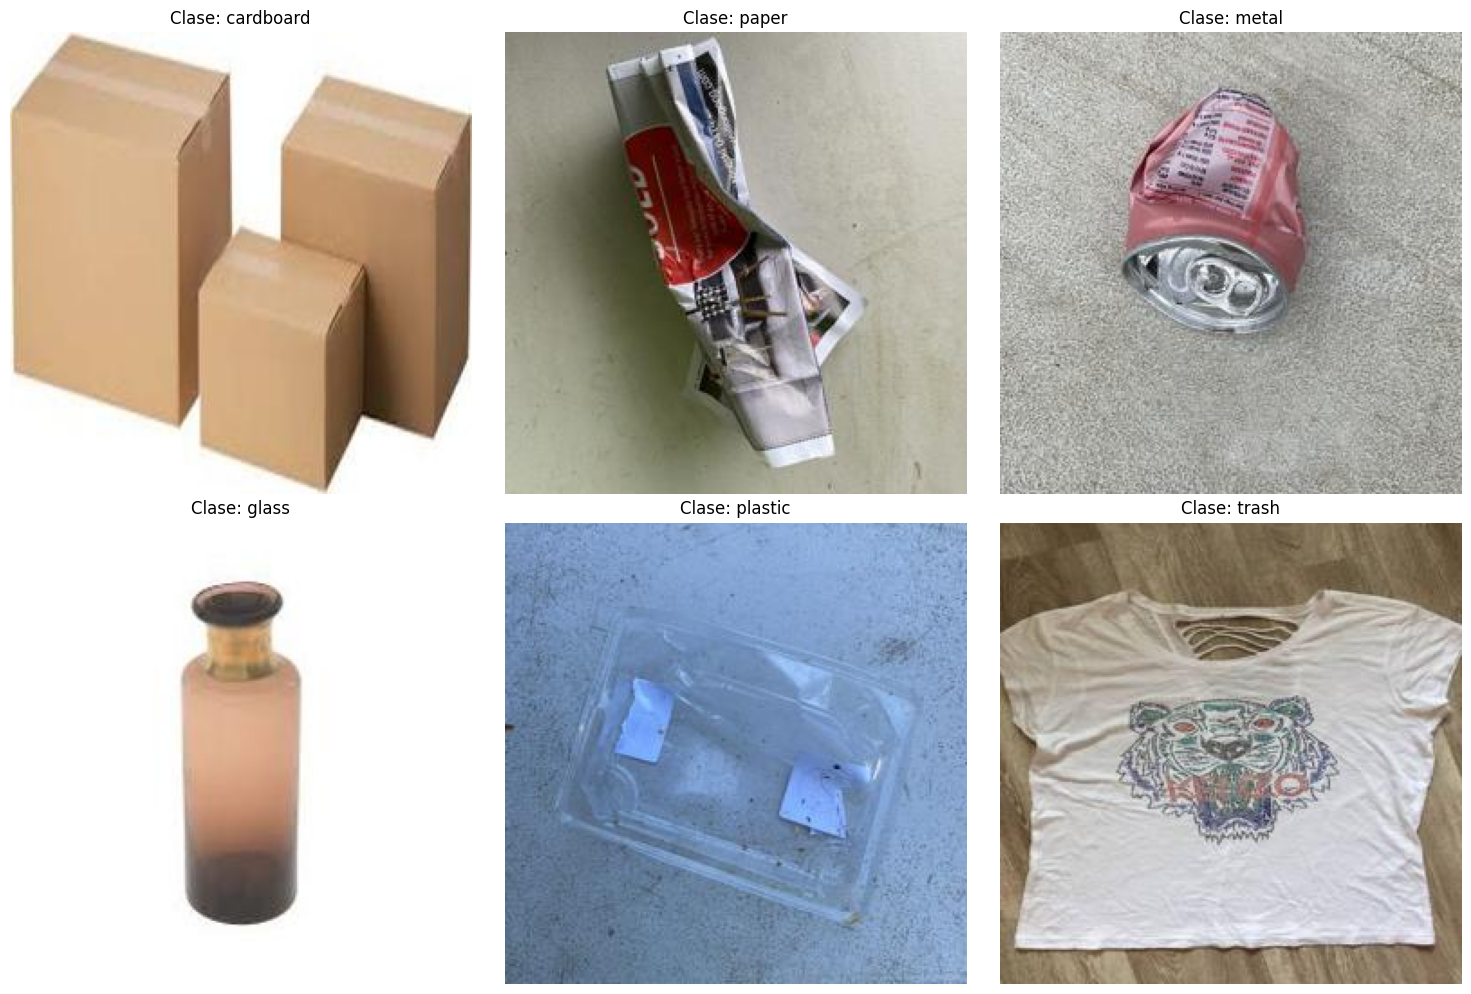

In [4]:
import os
import random
import matplotlib.pyplot as plt
from PIL import Image

# Apuntar un nivel más adentro donde realmente están las subcarpetas de categorías
dataset_path = os.path.join(path, "Garbage_Dataset_Classification", "images")

# Encontrar todas las carpetas (clases reales) dentro de esta ruta
classes = [d for d in os.listdir(dataset_path) if os.path.isdir(os.path.join(dataset_path, d))]
print(f"Clases reales encontradas: {classes}")

# Seleccionar un máximo de 6 clases para mostrar
classes_to_show = classes[:6]

plt.figure(figsize=(15, 10))

for i, class_name in enumerate(classes_to_show):
    class_dir = os.path.join(dataset_path, class_name)
    # Listar todos los archivos de imagen en la carpeta de la clase
    images = [f for f in os.listdir(class_dir) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]

    if images:
        # Elegir una imagen aleatoria de la clase
        random_img_name = random.choice(images)
        img_path = os.path.join(class_dir, random_img_name)

        # Cargar y mostrar la imagen
        img = Image.open(img_path)

        plt.subplot(2, 3, i + 1)
        plt.imshow(img)
        plt.title(f"Clase: {class_name}")
        plt.axis('off')

plt.tight_layout()
plt.show()

<IPython.core.display.Javascript object>

Haz clic en el botón 'Iniciar Detección' que aparecerá abajo para comenzar.


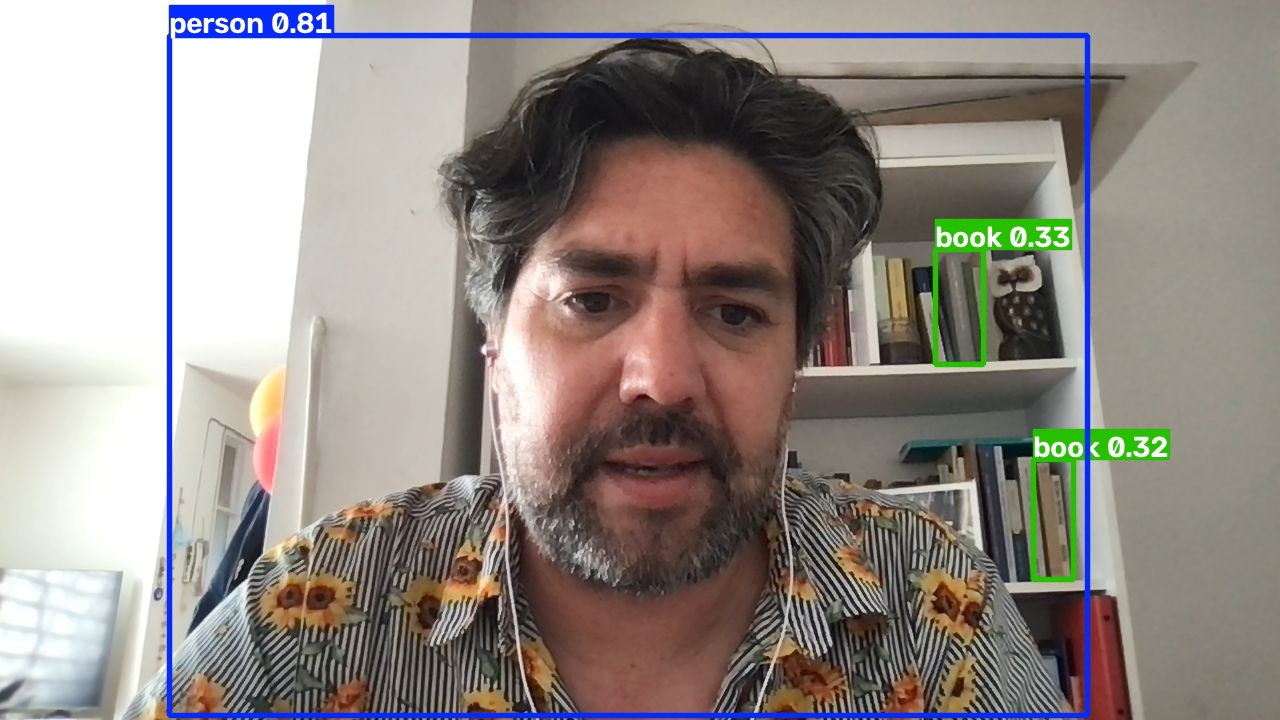

KeyboardInterrupt: 

In [7]:
!pip install ultralytics -q

import cv2
import numpy as np
import html
import io
import time
from IPython.display import display, Javascript, Image
from google.colab.output import eval_js
from base64 import b64decode, b64encode
from ultralytics import YOLO

# 1. Inicializar el modelo YOLOv8 Nano
model = YOLO('yolov8n.pt')

# 2. Funciones auxiliares para convertir imágenes de JS a OpenCV y viceversa
def js_to_image(js_reply):
  """Convierte el frame de JavaScript a una imagen OpenCV"""
  image_bytes = b64decode(js_reply.split(',')[1])
  jpg_as_np = np.frombuffer(image_bytes, dtype=np.uint8)
  img = cv2.imdecode(jpg_as_np, flags=1)
  return img

def bbox_to_bytes(bbox_array):
  """Convierte la imagen procesada con cajas a bytes para JS"""
  _, encoded_img = cv2.imencode('.jpg', bbox_array)
  bbox_bytes = encoded_img.tobytes()
  bbox_b64 = b64encode(bbox_bytes).decode('utf-8')
  return f"data:image/jpeg;base64,{bbox_b64}"

# 3. Código JavaScript para capturar el video de la cámara web
def start_video():
  js = Javascript('''
    async function create() {
      const div = document.createElement('div');
      const capture = document.createElement('button');
      const stop = document.createElement('button');
      capture.textContent = 'Iniciar Detección';
      capture.className = 'btn btn-primary';
      stop.textContent = 'Detener';
      stop.className = 'btn btn-danger';
      div.appendChild(capture);
      div.appendChild(stop);

      const video = document.createElement('video');
      video.style.display = 'block';
      const stream = await navigator.mediaDevices.getUserMedia({video: true});

      document.body.appendChild(div);
      div.appendChild(video);
      video.srcObject = stream;
      await video.play();

      // Forzar que el video coincida con el tamaño capturado
      google.colab.output.setIframeHeight(document.documentElement.scrollHeight, true);

      const canvas = document.createElement('canvas');
      canvas.width = video.videoWidth;
      canvas.height = video.videoHeight;
      const ctx = canvas.getContext('2d');

      let active = false;
      capture.onclick = () => { active = true; };
      stop.onclick = () => { active = false; stream.getVideoTracks()[0].stop(); div.remove(); };

      window.getFrame = async function() {
        if (!active) return null;
        ctx.drawImage(video, 0, 0);
        return canvas.toDataURL('image/jpeg', 0.8);
      };
    }
    create();
    ''')
  display(js)

# 4. Bucle principal para ejecutar la cámara y aplicar YOLO
try:
  start_video()
  print("Haz clic en el botón 'Iniciar Detección' que aparecerá abajo para comenzar.")

  # Esperar brevemente a que se inicie el script JS en el navegador
  time.sleep(2)

  # Creamos una imagen dummy de 1x1 píxeles para inicializar correctamente el display sin error
  dummy_img_bytes = b64decode("R0lGODlhAQABAIAAAAAAAP///yH5BAEAAAAALAAAAAABAAEAAAIBRAA7")
  output_display = display(Image(data=dummy_img_bytes), display_id=True)

  while True:
    # Verificar de forma segura si la función en JS ya existe
    js_func_exists = eval_js('typeof window.getFrame === "function"')
    if not js_func_exists:
      time.sleep(0.5)
      continue

    # Llamar a la función JS para obtener un frame de la cámara
    js_frame = eval_js('window.getFrame()')
    if js_frame is None:
      continue

    # Convertir a imagen OpenCV
    frame = js_to_image(js_frame)

    # Realizar detección con YOLOv8 (conf=0.3)
    results = model(frame, conf=0.3, verbose=False)

    # Dibujar las detecciones sobre el frame actual
    annotated_frame = results[0].plot()

    # Codificar la imagen procesada y actualizar la visualización
    img_bytes = bbox_to_bytes(annotated_frame)
    img_data = b64decode(img_bytes.split(',')[1])
    output_display.update(Image(data=img_data))

except Exception as err:
  print("Cámara detenida o error ocurrido:", err)

In [9]:
import os
import kagglehub
import shutil

# 1. Descargar un dataset alternativo de ropa completamente libre y público
print("Descargando dataset alternativo de ropa desde Kaggle...")
try:
    clothing_dataset_path = kagglehub.dataset_download("agrigorev/clothing-dataset-full")
    print("Ruta del dataset de ropa:", clothing_dataset_path)

    # 2. Mostrar la estructura de carpetas descargada
    print("\nEstructura del dataset de ropa:")
    for root, dirs, files in os.walk(clothing_dataset_path):
        level = root.replace(clothing_dataset_path, '').count(os.sep)
        indent = ' ' * 4 * (level)
        print(f"{indent}{os.path.basename(root)}/")
        subfiles = files[:3]
        for f in subfiles:
            print(f"{indent}    {f}")
        if len(files) > 3:
            print(f"{indent}    ... y {len(files) - 3} archivos más")
        if level > 1:
            break
except Exception as e:
    print("Error al descargar el dataset:", e)

Descargando dataset alternativo de ropa desde Kaggle...
Using Colab cache for faster access to the 'clothing-dataset-full' dataset.
Ruta del dataset de ropa: /kaggle/input/clothing-dataset-full

Estructura del dataset de ropa:
clothing-dataset-full/
    images.csv
    images_compressed/
        d619091d-fc8d-4730-9f3c-2a042e876272.jpg
        b0d71fba-23a7-4912-b6c6-16b7d8a5bd43.jpg
        7f17b410-d375-409e-b5b3-010122df5748.jpg
        ... y 5759 archivos más
    images_original/
        d619091d-fc8d-4730-9f3c-2a042e876272.jpg
        b0d71fba-23a7-4912-b6c6-16b7d8a5bd43.jpg
        7f17b410-d375-409e-b5b3-010122df5748.jpg
        ... y 5759 archivos más


In [10]:
import pandas as pd

# Cargar el archivo de metadatos del dataset de ropa
csv_path = os.path.join(clothing_dataset_path, "images.csv")
df_clothing = pd.read_csv(csv_path)

print("Información general del dataset:")
print(df_clothing.info())

print("\nPrimeras 5 filas del dataset de ropa:")
display(df_clothing.head())

print("\nDistribución de las categorías de ropa (top 15):")
print(df_clothing['label'].value_counts().head(15))

Información general del dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5403 entries, 0 to 5402
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   image      5403 non-null   object
 1   sender_id  5403 non-null   int64 
 2   label      5403 non-null   object
 3   kids       5403 non-null   bool  
dtypes: bool(1), int64(1), object(2)
memory usage: 132.0+ KB
None

Primeras 5 filas del dataset de ropa:


,image,sender_id,label,kids
0,4285fab0-751a-4b74-8e9b-43af05deee22,124,Not sure,False
1,ea7b6656-3f84-4eb3-9099-23e623fc1018,148,T-Shirt,False
2,00627a3f-0477-401c-95eb-92642cbe078d,94,Not sure,False
3,ea2ffd4d-9b25-4ca8-9dc2-bd27f1cc59fa,43,T-Shirt,False
4,3b86d877-2b9e-4c8b-a6a2-1d87513309d0,189,Shoes,False



Distribución de las categorías de ropa (top 15):
label
T-Shirt       1011
Longsleeve     699
Pants          692
Shoes          431
Shirt          378
Dress          357
Outwear        312
Shorts         308
Not sure       228
Hat            171
Skirt          155
Polo           120
Undershirt     118
Blazer         109
Hoodie         100
Name: count, dtype: int64


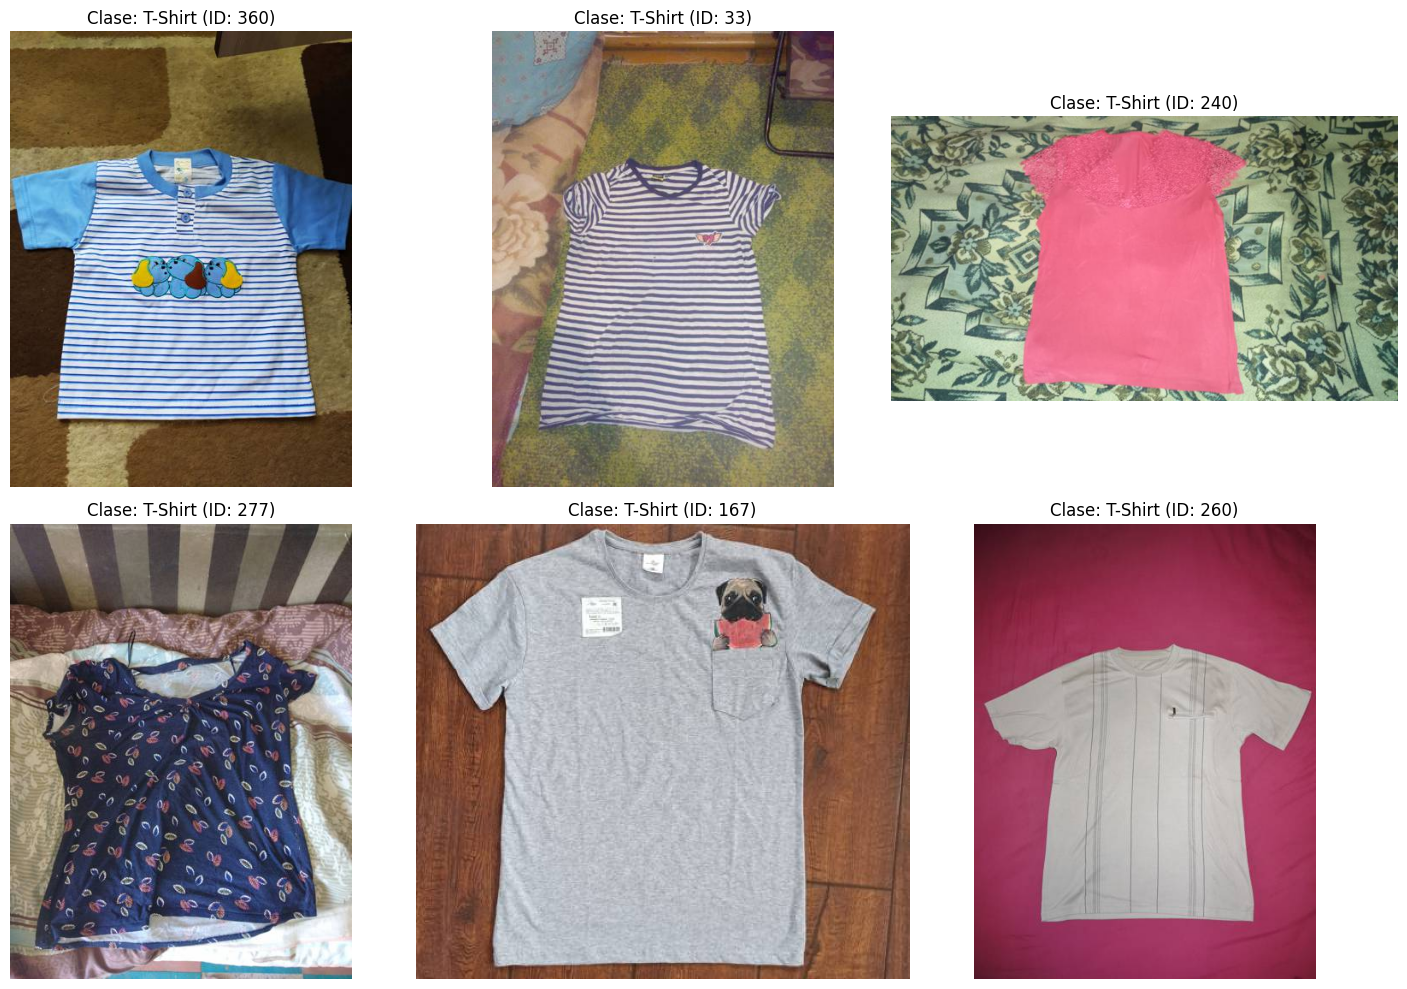

In [11]:
import os
import random
import matplotlib.pyplot as plt
from PIL import Image

# 1. Filtrar las filas que corresponden a poleras (T-Shirt)
df_tshirts = df_clothing[df_clothing['label'] == 'T-Shirt']

# 2. Definir la ruta de las imágenes comprimidas (para cargar más rápido)
images_dir = os.path.join(clothing_dataset_path, "images_compressed")

# 3. Tomar una muestra aleatoria de 6 imágenes de poleras
sample_tshirts = df_tshirts.sample(n=min(6, len(df_tshirts)), random_state=random.randint(1, 1000))

# 4. Graficar las imágenes
plt.figure(figsize=(15, 10))

for i, (idx, row) in enumerate(sample_tshirts.iterrows()):
    image_name = row['image']
    # El CSV no siempre tiene la extensión .jpg incluida, nos aseguramos de que termine en .jpg
    if not image_name.endswith('.jpg'):
        image_name += '.jpg'

    img_path = os.path.join(images_dir, image_name)

    try:
        img = Image.open(img_path)
        plt.subplot(2, 3, i + 1)
        plt.imshow(img)
        plt.title(f"Clase: T-Shirt (ID: {row['sender_id']})")
        plt.axis('off')
    except Exception as e:
        print(f"No se pudo cargar la imagen {image_name}: {e}")

plt.tight_layout()
plt.show()

In [12]:
import os
import shutil
from sklearn.model_selection import train_test_split

# 1. Definir directorios de salida para el formato YOLO
base_yolo_dir = "/content/dataset_ropa_yolo"
img_train_dir = os.path.join(base_yolo_dir, "images/train")
img_val_dir = os.path.join(base_yolo_dir, "images/val")
label_train_dir = os.path.join(base_yolo_dir, "labels/train")
label_val_dir = os.path.join(base_yolo_dir, "labels/val")

for d in [img_train_dir, img_val_dir, label_train_dir, label_val_dir]:
    os.makedirs(d, exist_ok=True)

# 2. Filtrar únicamente las poleras del DataFrame
df_tshirts = df_clothing[df_clothing['label'] == 'T-Shirt'].copy()

# Para este ejemplo, usaremos una muestra representativa (por ejemplo, 500 imágenes)
# para no sobrecargar el almacenamiento y agilizar el entrenamiento
sample_size = min(500, len(df_tshirts))
df_sample = df_tshirts.sample(n=sample_size, random_state=42)

# 3. Separar en conjuntos de entrenamiento (80%) y validación (20%)
train_df, val_df = train_test_split(df_sample, test_size=0.2, random_state=42)

# Definimos el ID de clase que le daremos a 'T-Shirt' (por ejemplo, clase 0)
CLASS_ID = 0

def preparar_datos_yolo(df, dest_img_dir, dest_label_dir):
    copiados = 0
    for idx, row in df.iterrows():
        img_name = row['image']
        if not img_name.endswith('.jpg'):
            img_name += '.jpg'

        src_img_path = os.path.join(images_dir, img_name)

        if os.path.exists(src_img_path):
            # Copiar imagen al directorio de destino
            shutil.copy(src_img_path, os.path.join(dest_img_dir, img_name))

            # Crear el archivo de etiquetas .txt correspondiente
            # El formato YOLO es: [class_id] [x_center] [y_center] [width] [height] (todos valores entre 0 y 1)
            # Como no tenemos bounding boxes exactos, definimos una caja que cubra el 100% de la imagen
            label_name = img_name.replace('.jpg', '.txt')
            label_file_path = os.path.join(dest_label_dir, label_name)

            with open(label_file_path, 'w') as f:
                # class_id, x_center=0.5, y_center=0.5, width=1.0, height=1.0
                f.write(f"{CLASS_ID} 0.5 0.5 1.0 1.0\n")

            copiados += 1
    return copiados

# Procesar ambos conjuntos
cant_train = preparar_datos_yolo(train_df, img_train_dir, label_train_dir)
cant_val = preparar_datos_yolo(val_df, img_val_dir, label_val_dir)

print(f"Proceso completado:")
print(f"- Imágenes de entrenamiento creadas: {cant_train}")
print(f"- Imágenes de validación creadas: {cant_val}")
print(f"Directorio del dataset listo para YOLO en: {base_yolo_dir}")

Proceso completado:
- Imágenes de entrenamiento creadas: 400
- Imágenes de validación creadas: 100
Directorio del dataset listo para YOLO en: /content/dataset_ropa_yolo


In [13]:
import yaml

# 1. Definir la configuración del dataset en un diccionario
yolo_config = {
    'path': base_yolo_dir,               # Ruta raíz del dataset
    'train': 'images/train',             # Carpeta de imágenes de entrenamiento (relativa a 'path')
    'val': 'images/val',                 # Carpeta de imágenes de validación (relativa a 'path')
    'names': {
        0: 'T-Shirt'                     # ID de la clase y su respectivo nombre
    }
}

# 2. Guardar la configuración en un archivo 'dataset.yaml'
yaml_path = os.path.join(base_yolo_dir, "dataset.yaml")
with open(yaml_path, 'w') as f:
    yaml.dump(yolo_config, f, default_flow_style=False)

print(f"Archivo de configuración YOLO guardado con éxito en: {yaml_path}")

# 3. Mostrar el contenido creado
print("\nContenido del dataset.yaml:")
with open(yaml_path, 'r') as f:
    print(f.read())

Archivo de configuración YOLO guardado con éxito en: /content/dataset_ropa_yolo/dataset.yaml

Contenido del dataset.yaml:
names:
  0: T-Shirt
path: /content/dataset_ropa_yolo
train: images/train
val: images/val



In [14]:
from ultralytics import YOLO

# 1. Cargar el modelo preentrenado YOLOv8 Nano
model = YOLO('yolov8n.pt')

# 2. Iniciar el entrenamiento con nuestro nuevo dataset de ropa
# Nota: Usamos pocas épocas (ej. 5) para probar que todo corra correctamente.
# Puedes aumentarlo a 30 o 50 para obtener mejores resultados.
results = model.train(
    data=yaml_path,     # Ruta al archivo dataset.yaml que acabamos de crear
    epochs=5,           # Cantidad de épocas de entrenamiento
    imgsz=640,          # Tamaño de las imágenes de entrada
    batch=16,           # Tamaño del lote (batch size)
    device='cpu'        # Cambiar a '0' o 'cuda' si tienes la GPU activada en Colab
)

Ultralytics 8.4.215 🚀 Python-3.13.18 torch-2.14.1+cpu CPU (Intel Xeon CPU @ 2.20GHz)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dataset_ropa_yolo/dataset.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=5, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=None, opset=None, optimize=

<IPython.core.display.Javascript object>

Haz clic en 'Iniciar Detección de Poleras' para probar tu modelo personalizado en tiempo real.


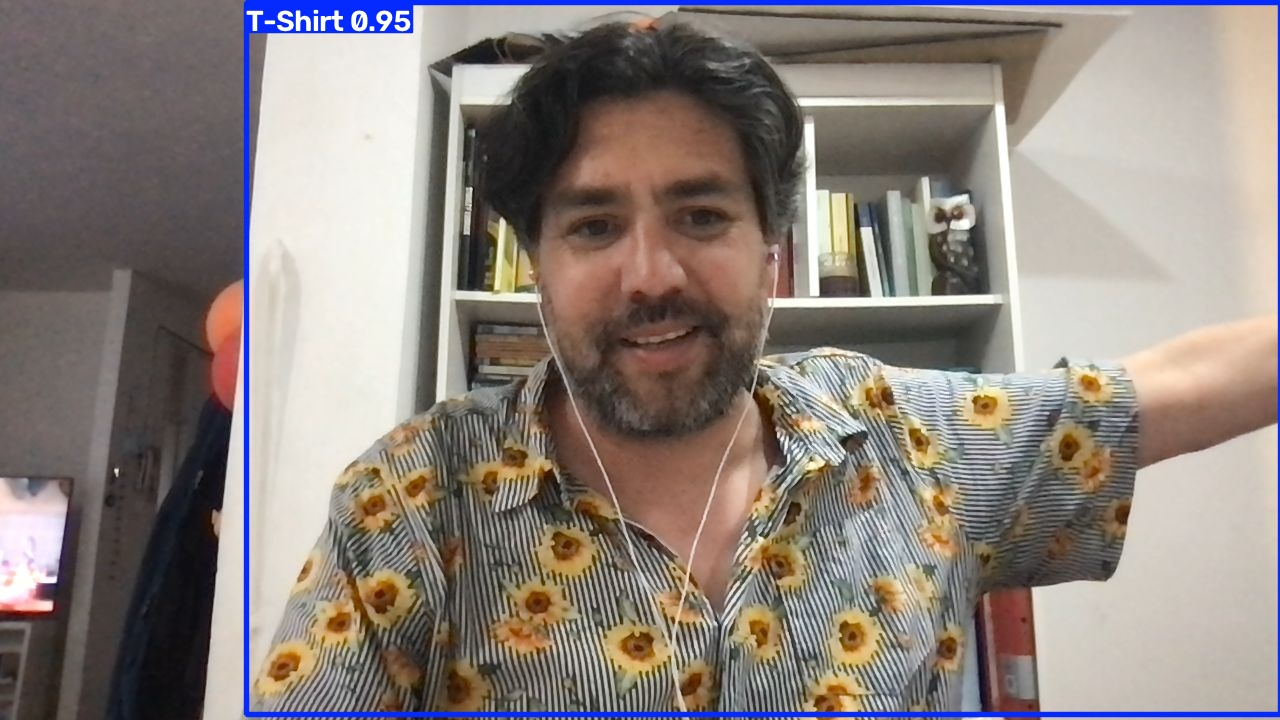

KeyboardInterrupt: 

In [15]:
import cv2
import numpy as np
import html
import io
import time
from IPython.display import display, Javascript, Image
from google.colab.output import eval_js
from base64 import b64decode, b64encode
from ultralytics import YOLO

# 1. Cargar tus pesos personalizados entrenados ('best.pt')
custom_weights_path = '/content/runs/detect/train/weights/best.pt'
custom_model = YOLO(custom_weights_path)

# 2. Funciones auxiliares para convertir imágenes de JS a OpenCV y viceversa
def js_to_image_custom(js_reply):
  image_bytes = b64decode(js_reply.split(',')[1])
  jpg_as_np = np.frombuffer(image_bytes, dtype=np.uint8)
  img = cv2.imdecode(jpg_as_np, flags=1)
  return img

def bbox_to_bytes_custom(bbox_array):
  _, encoded_img = cv2.imencode('.jpg', bbox_array)
  bbox_bytes = encoded_img.tobytes()
  bbox_b64 = b64encode(bbox_bytes).decode('utf-8')
  return f"data:image/jpeg;base64,{bbox_b64}"

# 3. Código JavaScript para capturar el video de la cámara web
def start_video_custom():
  js = Javascript('''
    async function create() {
      const div = document.createElement('div');
      const capture = document.createElement('button');
      const stop = document.createElement('button');
      capture.textContent = 'Iniciar Detección de Poleras';
      capture.className = 'btn btn-success';
      stop.textContent = 'Detener';
      stop.className = 'btn btn-danger';
      div.appendChild(capture);
      div.appendChild(stop);

      const video = document.createElement('video');
      video.style.display = 'block';
      const stream = await navigator.mediaDevices.getUserMedia({video: true});

      document.body.appendChild(div);
      div.appendChild(video);
      video.srcObject = stream;
      await video.play();

      google.colab.output.setIframeHeight(document.documentElement.scrollHeight, true);

      const canvas = document.createElement('canvas');
      canvas.width = video.videoWidth;
      canvas.height = video.videoHeight;
      const ctx = canvas.getContext('2d');

      let active = false;
      capture.onclick = () => { active = true; };
      stop.onclick = () => { active = false; stream.getVideoTracks()[0].stop(); div.remove(); };

      window.getFrameCustom = async function() {
        if (!active) return null;
        ctx.drawImage(video, 0, 0);
        return canvas.toDataURL('image/jpeg', 0.8);
      };
    }
    create();
    ''')
  display(js)

# 4. Bucle principal para ejecutar la cámara y aplicar el modelo de poleras
try:
  start_video_custom()
  print("Haz clic en 'Iniciar Detección de Poleras' para probar tu modelo personalizado en tiempo real.")

  time.sleep(2)

  dummy_img_bytes = b64decode("R0lGODlhAQABAIAAAAAAAP///yH5BAEAAAAALAAAAAABAAEAAAIBRAA7")
  output_display = display(Image(data=dummy_img_bytes), display_id=True)

  while True:
    js_func_exists = eval_js('typeof window.getFrameCustom === "function"')
    if not js_func_exists:
      time.sleep(0.5)
      continue

    js_frame = eval_js('window.getFrameCustom()')
    if js_frame is None:
      continue

    frame = js_to_image_custom(js_frame)

    # Realizar detección con el modelo de poleras entrenado
    results = custom_model(frame, conf=0.3, verbose=False)

    # Dibujar predicciones sobre la pantalla
    annotated_frame = results[0].plot()

    # Actualizar la salida en pantalla
    img_bytes = bbox_to_bytes_custom(annotated_frame)
    img_data = b64decode(img_bytes.split(',')[1])
    output_display.update(Image(data=img_data))

except Exception as err:
  print("Cámara detenida o finalizada:", err)

In [16]:
import os
import shutil
import pandas as pd
from sklearn.model_selection import train_test_split

# 1. Definir rutas del dataset unificado
union_dir = "/content/dataset_unificado_yolo"
union_img_train = os.path.join(union_dir, "images/train")
union_img_val = os.path.join(union_dir, "images/val")
union_label_train = os.path.join(union_dir, "labels/train")
union_label_val = os.path.join(union_dir, "labels/val")

for d in [union_img_train, union_img_val, union_label_train, union_label_val]:
    os.makedirs(d, exist_ok=True)

# 2. Definir el mapeo de clases unificado
class_mapping = {
    'cardboard': 0,
    'glass': 1,
    'metal': 2,
    'paper': 3,
    'plastic': 4,
    'trash': 5,
    'T-Shirt': 6
}

# 3. Recopilar datos de Basura (Garbage Dataset)
garbage_base_path = os.path.join(path, "Garbage_Dataset_Classification", "images")
garbage_records = []

for class_name in ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']:
    class_folder = os.path.join(garbage_base_path, class_name)
    if os.path.exists(class_folder):
        for img_file in os.listdir(class_folder):
            if img_file.lower().endswith(('.png', '.jpg', '.jpeg')):
                garbage_records.append({
                    'image_path': os.path.join(class_folder, img_file),
                    'image_name': f"garbage_{class_name}_{img_file}",
                    'label': class_name
                })

df_garbage_union = pd.DataFrame(garbage_records)
# Tomar una muestra representativa de basura para balancear (ej. 80 imágenes por clase)
df_garbage_sampled = df_garbage_union.groupby('label').apply(lambda x: x.sample(n=min(80, len(x)), random_state=42)).reset_index(drop=True)

# 4. Recopilar datos de Ropa (T-Shirts)
clothing_images_dir = os.path.join(clothing_dataset_path, "images_compressed")
df_tshirts_union = df_clothing[df_clothing['label'] == 'T-Shirt'].copy()
df_tshirts_sampled = df_tshirts_union.sample(n=min(480, len(df_tshirts_union)), random_state=42)

clothing_records = []
for idx, row in df_tshirts_sampled.iterrows():
    img_name = row['image']
    if not img_name.endswith('.jpg'):
        img_name += '.jpg'
    src_path = os.path.join(clothing_images_dir, img_name)
    if os.path.exists(src_path):
        clothing_records.append({
            'image_path': src_path,
            'image_name': f"clothing_{img_name}",
            'label': 'T-Shirt'
        })

df_clothing_sampled = pd.DataFrame(clothing_records)

# 5. Combinar ambos DataFrames
df_final_union = pd.concat([df_garbage_sampled, df_clothing_sampled], ignore_index=True)

# 6. Separar en Entrenamiento (80%) y Validación (20%)
train_union, val_union = train_test_split(df_final_union, test_size=0.2, stratify=df_final_union['label'], random_state=42)

def copiar_y_etiquetar_union(df, dest_img, dest_label):
    copiados = 0
    for idx, row in df.iterrows():
        src_img = row['image_path']
        new_name = row['image_name']
        class_id = class_mapping[row['label']]

        # Copiar imagen
        dest_img_path = os.path.join(dest_img, new_name)
        shutil.copy(src_img, dest_img_path)

        # Crear etiqueta YOLO (caja completa)
        label_name = os.path.splitext(new_name)[0] + ".txt"
        dest_label_path = os.path.join(dest_label, label_name)
        with open(dest_label_path, 'w') as f:
            f.write(f"{class_id} 0.5 0.5 1.0 1.0\n")

        copiados += 1
    return copiados

cant_train_union = copiar_y_etiquetar_union(train_union, union_img_train, union_label_train)
cant_val_union = copiar_y_etiquetar_union(val_union, union_img_val, union_label_val)

print(f"Dataset unificado creado con éxito en: {union_dir}")
print(f"- Imágenes de entrenamiento: {cant_train_union}")
print(f"- Imágenes de validación: {cant_val_union}")

/tmp/ipykernel_1300/1857863836.py:44: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_garbage_sampled = df_garbage_union.groupby('label').apply(lambda x: x.sample(n=min(80, len(x)), random_state=42)).reset_index(drop=True)


Dataset unificado creado con éxito en: /content/dataset_unificado_yolo
- Imágenes de entrenamiento: 768
- Imágenes de validación: 192


In [17]:
import yaml

# Guardar la configuración yaml
union_config = {
    'path': union_dir,
    'train': 'images/train',
    'val': 'images/val',
    'names': {
        0: 'cardboard',
        1: 'glass',
        2: 'metal',
        3: 'paper',
        4: 'plastic',
        5: 'trash',
        6: 'T-Shirt'
    }
}

union_yaml_path = os.path.join(union_dir, "dataset_union.yaml")
with open(union_yaml_path, 'w') as f:
    yaml.dump(union_config, f, default_flow_style=False)

print("Configuración YAML unificada guardada:")
with open(union_yaml_path, 'r') as f:
    print(f.read())

Configuración YAML unificada guardada:
names:
  0: cardboard
  1: glass
  2: metal
  3: paper
  4: plastic
  5: trash
  6: T-Shirt
path: /content/dataset_unificado_yolo
train: images/train
val: images/val



In [18]:
# Iniciar entrenamiento del modelo unificado
# Nota: Usamos 5 épocas para comprobar de forma ultra rápida que todo funciona correctamente.
model_union = YOLO('yolov8n.pt')

results_union = model_union.train(
    data=union_yaml_path,
    epochs=5,
    imgsz=640,
    batch=16,
    device='cpu'
)

Ultralytics 8.4.215 🚀 Python-3.13.18 torch-2.14.1+cpu CPU (Intel Xeon CPU @ 2.20GHz)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dataset_unificado_yolo/dataset_union.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=5, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train-2, nbs=64, nms=None, opset=No

### Estructura de Ejemplo de Etiqueta YOLO creada
Cada archivo `.txt` generado contendrá una sola línea de texto indicando la clase y la caja contenedora:
```text
0 0.5 0.5 1.0 1.0
```
Esto le indica a YOLO que la totalidad de la imagen corresponde a la clase de ropa configurada (en este caso, la clase `0`).

<IPython.core.display.Javascript object>

Haz clic en 'Iniciar Detección Unificada' para probar el nuevo modelo híbrido.


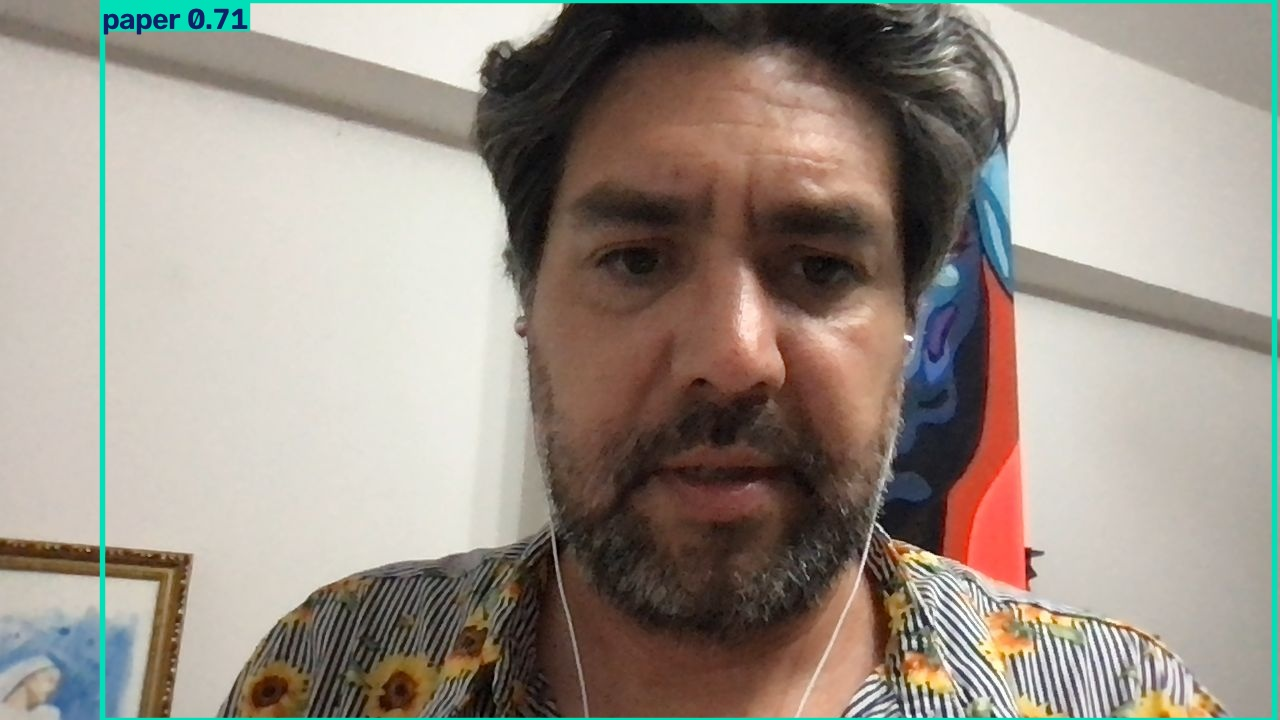

KeyboardInterrupt: 

In [19]:
import cv2
import numpy as np
import html
import io
import time
from IPython.display import display, Javascript, Image
from google.colab.output import eval_js
from base64 import b64decode, b64encode
from ultralytics import YOLO

# 1. Cargar los pesos del modelo unificado recién entrenado
weights_union_path = '/content/runs/detect/train-2/weights/best.pt'
model_union_cam = YOLO(weights_union_path)

# 2. Funciones de conversión
def js_to_image_union(js_reply):
  image_bytes = b64decode(js_reply.split(',')[1])
  jpg_as_np = np.frombuffer(image_bytes, dtype=np.uint8)
  img = cv2.imdecode(jpg_as_np, flags=1)
  return img

def bbox_to_bytes_union(bbox_array):
  _, encoded_img = cv2.imencode('.jpg', bbox_array)
  bbox_bytes = encoded_img.tobytes()
  bbox_b64 = b64encode(bbox_bytes).decode('utf-8')
  return f"data:image/jpeg;base64,{bbox_b64}"

# 3. Interfaz JavaScript para capturar la cámara
def start_video_union():
  js = Javascript('''
    async function create() {
      const div = document.createElement('div');
      const capture = document.createElement('button');
      const stop = document.createElement('button');
      capture.textContent = 'Iniciar Detección Unificada';
      capture.className = 'btn btn-primary';
      stop.textContent = 'Detener';
      stop.className = 'btn btn-danger';
      div.appendChild(capture);
      div.appendChild(stop);

      const video = document.createElement('video');
      video.style.display = 'block';
      const stream = await navigator.mediaDevices.getUserMedia({video: true});

      document.body.appendChild(div);
      div.appendChild(video);
      video.srcObject = stream;
      await video.play();

      google.colab.output.setIframeHeight(document.documentElement.scrollHeight, true);

      const canvas = document.createElement('canvas');
      canvas.width = video.videoWidth;
      canvas.height = video.videoHeight;
      const ctx = canvas.getContext('2d');

      let active = false;
      capture.onclick = () => { active = true; };
      stop.onclick = () => { active = false; stream.getVideoTracks()[0].stop(); div.remove(); };

      window.getFrameUnion = async function() {
        if (!active) return null;
        ctx.drawImage(video, 0, 0);
        return canvas.toDataURL('image/jpeg', 0.8);
      };
    }
    create();
    ''')
  display(js)

# 4. Loop de ejecución
try:
  start_video_union()
  print("Haz clic en 'Iniciar Detección Unificada' para probar el nuevo modelo híbrido.")

  time.sleep(2)
  dummy_img_bytes = b64decode("R0lGODlhAQABAIAAAAAAAP///yH5BAEAAAAALAAAAAABAAEAAAIBRAA7")
  output_display = display(Image(data=dummy_img_bytes), display_id=True)

  while True:
    js_func_exists = eval_js('typeof window.getFrameUnion === "function"')
    if not js_func_exists:
      time.sleep(0.5)
      continue

    js_frame = eval_js('window.getFrameUnion()')
    if js_frame is None:
      continue

    frame = js_to_image_union(js_frame)

    # Detección simultánea (conf=0.25 para dar más margen a las clases de basura poco entrenadas)
    results = model_union_cam(frame, conf=0.25, verbose=False)
    annotated_frame = results[0].plot()

    img_bytes = bbox_to_bytes_union(annotated_frame)
    img_data = b64decode(img_bytes.split(',')[1])
    output_display.update(Image(data=img_data))

except Exception as err:
  print("Cámara finalizada o desconectada:", err)